# Olist Data Cleaning — Power Query M to Python (Google Colab)

**الغرض:** تحويل استعلامات Power Query M المرفقة إلى خطوات Python باستخدام `pandas`، مع الحفاظ على قواعد التنظيف الموجودة في M، وإضافة فحص جودة البيانات، وتحليل استكشافي EDA، ورسوم بيانية، وتقارير تحقق وتصدير مناسبة للتكامل مع قاعدة بيانات.

## الاستعلامات المشمولة

- **Raw / cleaned:** `olist_customers_dataset`, `olist_geolocation_dataset`, `olist_order_items_dataset`, `olist_order_payments_dataset`, `olist_order_reviews_dataset`, `olist_orders_dataset`, `olist_products_dataset`, `olist_sellers_dataset`, `product_category_name_translation`.
- **Derived:** `Order_Payments_Summary`, `Order_Reconciliation`, `Order_Reconciliation_Exceptions`, `Junction_table_loc`.

## قبل التشغيل

ارفع ملفات CSV التسعة الأصلية (أو ملف ZIP يحتوي عليها) عند ظهور نافذة الرفع. أسماء الملفات المطلوبة يجب أن تطابق أسماء Olist الأصلية. لا يلزم استخدام مسارات Windows الموجودة في M؛ الكود يبحث عن الملفات المرفوعة.

> **مبدأ التحويل:** لا نحذف صفوفًا أو نزيل تكرارات أو نستبدل قيمًا إضافية من عندنا. خطوات التنظيف الواردة في M تُطبق كما هي قدر الإمكان، ويُسجل التحويل العددي/التاريخي غير القابل للقراءة في تقرير تشخيصي بدل إخفائه.

## 1. إعداد البيئة

In [2]:
from pathlib import Path
import os
import re
import zipfile
import warnings
import pandas as pd
import numpy as np
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 100)

# Colab: /content. Local Jupyter: current working directory.
DATA_DIR = Path(os.environ.get("OLIST_DATA_DIR", "/content" if Path("/content").exists() else Path.cwd()))
OUTPUT_DIR = DATA_DIR / "olist_python_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED_FILES = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
]

print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

Data directory: /content
Output directory: /content/olist_python_output


## 2. رفع ملفات البيانات (Colab)

In [3]:
def find_csv(filename: str):
    """Find a required CSV by exact filename anywhere under DATA_DIR."""
    matches = list(DATA_DIR.rglob(filename))
    # Exclude files in the output folder if a stale export exists there.
    matches = [p for p in matches if OUTPUT_DIR not in p.parents]
    return matches[0] if matches else None

missing_before_upload = [name for name in REQUIRED_FILES if find_csv(name) is None]
if missing_before_upload:
    try:
        from google.colab import files
        print("Missing files:", missing_before_upload)
        print("Choose all nine CSV files, or one ZIP containing them.")
        uploaded = files.upload()
        for uploaded_name, uploaded_bytes in uploaded.items():
            destination = DATA_DIR / Path(uploaded_name).name
            destination.write_bytes(uploaded_bytes)
            if destination.suffix.lower() == ".zip":
                extract_dir = DATA_DIR / "olist_uploaded_zip"
                extract_dir.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(destination, "r") as archive:
                    archive.extractall(extract_dir)
        print("Upload complete.")
    except ImportError:
        print("Google Colab upload UI is unavailable. Place the CSV files under DATA_DIR:", DATA_DIR)

file_paths = {name: find_csv(name) for name in REQUIRED_FILES}
missing = [name for name, path in file_paths.items() if path is None]
if missing:
    raise FileNotFoundError(
        "These required CSV files were not found: " + ", ".join(missing) +
        "\nUpload them to Colab or set OLIST_DATA_DIR to the folder containing them."
    )

pd.DataFrame({"file": list(file_paths), "path_found": [str(p) for p in file_paths.values()]})

Missing files: ['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']
Choose all nine CSV files, or one ZIP containing them.


Saving Olist Dataset.zip to Olist Dataset.zip
Upload complete.


,file,path_found
0,olist_customers_dataset.csv,/content/olist_uploaded_zip/Olist Dataset/olist_customers_dataset.csv
1,olist_geolocation_dataset.csv,/content/olist_uploaded_zip/Olist Dataset/olist_geolocation_dataset.csv
2,olist_order_items_dataset.csv,/content/olist_uploaded_zip/Olist Dataset/olist_order_items_dataset.csv
3,olist_order_payments_dataset.csv,/content/olist_uploaded_zip/Olist Dataset/olist_order_payments_dataset.csv
4,olist_order_reviews_dataset.csv,/content/olist_uploaded_zip/Olist Dataset/olist_order_reviews_dataset.csv
5,olist_orders_dataset.csv,/content/olist_uploaded_zip/Olist Dataset/olist_orders_dataset.csv
6,olist_products_dataset.csv,/content/olist_uploaded_zip/Olist Dataset/olist_products_dataset.csv
7,olist_sellers_dataset.csv,/content/olist_uploaded_zip/Olist Dataset/olist_sellers_dataset.csv
8,product_category_name_translation.csv,/content/olist_uploaded_zip/Olist Dataset/product_category_name_translation.csv


## 3. دوال مساعدة للتنظيف والتحويل

- `Text.Trim` يقابله إزالة المسافات من أول وآخر النص.
- `Text.Clean` يقابله حذف محارف التحكم غير المرئية.
- التحويلات الرقمية والتاريخية تعرض عدد القيم غير القابلة للتحويل؛ هذا تشخيص فقط ولا يُسقط الصفوف.

In [5]:
parse_issues = []

def read_csv_flexible(path: Path) -> pd.DataFrame:
    """Read CSV as text first to preserve IDs and leading zeros; use encoding fallback."""
    last_error = None
    for encoding in ("utf-8-sig", "cp1252", "latin1"):
        try:
            return pd.read_csv(
                path,
                encoding=encoding,
                dtype="string",
                keep_default_na=True,
                low_memory=False,
                on_bad_lines="error",
            )
        except UnicodeDecodeError as exc:
            last_error = exc
    raise UnicodeError(f"Could not decode {path.name} with supported encodings") from last_error


def clean_text_series(series: pd.Series) -> pd.Series:
    """Approximate Power Query Text.Clean followed by Text.Trim; preserve missing values."""
    result = series.astype("string")
    result = result.str.replace(r"[\x00-\x1F\x7F]", "", regex=True)
    return result.str.strip()


def clean_text_columns(df: pd.DataFrame, columns) -> pd.DataFrame:
    df = df.copy()
    for column in columns:
        if column in df.columns:
            df[column] = clean_text_series(df[column])
    return df


def parse_numeric(df: pd.DataFrame, column: str, integer: bool = False) -> pd.DataFrame:
    """Convert a column and report nonblank values that failed numeric conversion."""
    df = df.copy()
    original = df[column].astype("string")
    cleaned = clean_text_series(original)
    converted = pd.to_numeric(cleaned, errors="coerce")
    invalid = original.notna() & cleaned.ne("") & converted.isna()
    if invalid.any():
        parse_issues.append({
            "table": CURRENT_TABLE,
            "column": column,
            "issue": "numeric_parse_failure",
            "count": int(invalid.sum()),
            "examples": " | ".join(original[invalid].head(5).astype(str).tolist()),
        })
    if integer:
        # Nullable integer dtype supports genuine missing values.
        converted = converted.round().astype("Int64")
    df[column] = converted
    return df


def parse_datetime(df: pd.DataFrame, column: str, date_only: bool = False) -> pd.DataFrame:
    """Parse date/timestamp values; record malformed nonblank values instead of dropping rows."""
    df = df.copy()
    original = df[column].astype("string")
    cleaned = clean_text_series(original)
    converted = pd.to_datetime(cleaned, errors="coerce")
    invalid = original.notna() & cleaned.ne("") & converted.isna()
    if invalid.any():
        parse_issues.append({
            "table": CURRENT_TABLE,
            "column": column,
            "issue": "datetime_parse_failure",
            "count": int(invalid.sum()),
            "examples": " | ".join(original[invalid].head(5).astype(str).tolist()),
        })
    if date_only:
        converted = converted.dt.normalize()
    df[column] = converted
    return df


def require_columns(df: pd.DataFrame, columns, table_name: str):
    missing_columns = [c for c in columns if c not in df.columns]
    if missing_columns:
        raise ValueError(f"{table_name}: missing expected columns {missing_columns}. Found: {list(df.columns)}")


def load_source(filename: str, table_name: str) -> pd.DataFrame:
    global CURRENT_TABLE
    CURRENT_TABLE = table_name
    df = read_csv_flexible(file_paths[filename])
    print(f"Loaded {table_name}: {len(df):,} rows × {len(df.columns)} columns")
    return df

## 4. Query: `olist_customers_dataset`

تطبيق استبدال النص الحرفي `??????` بـ `brasilia` ثم `?????` بـ `franca` على `customer_city` كما ورد في M. لم نفترض أسماء المدن المقصودة؛ لو هذه العلامات ناتجة عن تلف Encoding، راجع القيم المتأثرة قبل اعتمادها.

In [6]:
CURRENT_TABLE = "olist_customers_dataset"
customers = load_source("olist_customers_dataset.csv", CURRENT_TABLE)
require_columns(customers, ["customer_id", "customer_unique_id", "customer_zip_code_prefix", "customer_city", "customer_state"], CURRENT_TABLE)
customers = clean_text_columns(customers, customers.columns)
customers["customer_city"] = customers["customer_city"].str.replace("??????", "brasilia", regex=False)
customers["customer_city"] = customers["customer_city"].str.replace("?????", "franca", regex=False)
customers.head()

Loaded olist_customers_dataset: 99,441 rows × 5 columns


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


## 5. Query: `olist_geolocation_dataset`

الكود الأصلي يحوّل خطوط العرض والطول إلى أرقام أولًا، ثم إلى **نصوص** في الخطوة النهائية أثناء `Text.Trim` و`Text.Clean`. لذلك نحافظ هنا على تمثيلهما النصي في جدول التنظيف النهائي، مع فحص أن القيم قابلة للتحويل لأرقام.

In [7]:
CURRENT_TABLE = "olist_geolocation_dataset"
geolocation = load_source("olist_geolocation_dataset.csv", CURRENT_TABLE)
require_columns(geolocation, ["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng", "geolocation_city", "geolocation_state"], CURRENT_TABLE)
geolocation = clean_text_columns(geolocation, geolocation.columns)
for column in ["geolocation_lat", "geolocation_lng"]:
    numeric_check = pd.to_numeric(geolocation[column], errors="coerce")
    invalid = geolocation[column].notna() & geolocation[column].ne("") & numeric_check.isna()
    if invalid.any():
        parse_issues.append({"table": CURRENT_TABLE, "column": column, "issue": "coordinate_numeric_check_failure", "count": int(invalid.sum()), "examples": " | ".join(geolocation.loc[invalid, column].head(5).astype(str))})
geolocation.head()

Loaded olist_geolocation_dataset: 1,000,163 rows × 5 columns


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,01037,-23.54562128115268,-46.63929204800168,sao paulo,SP
1,01046,-23.546081127035535,-46.64482029837157,sao paulo,SP
2,01046,-23.54612896641469,-46.64295148361138,sao paulo,SP
3,01041,-23.5443921648681,-46.63949930627844,sao paulo,SP
4,01035,-23.541577961711493,-46.64160722329613,sao paulo,SP


## 6. Query: `olist_order_items_dataset`

الترتيب محفوظ: تنظيف النصوص، تحويل تاريخ الشحن إلى Date (وليس Time)، أخذ القيمة المطلقة لـ `price`، ثم تعويض القيم الفارغة في `price` بـ `145.95` كما نصّ M.

In [8]:
CURRENT_TABLE = "olist_order_items_dataset"
order_items = load_source("olist_order_items_dataset.csv", CURRENT_TABLE)
require_columns(order_items, ["order_id", "order_item_id", "product_id", "seller_id", "shipping_limit_date", "price", "freight_value"], CURRENT_TABLE)
text_cols = ["order_id", "product_id", "seller_id", "shipping_limit_date", "order_item_id", "price", "freight_value"]
order_items = clean_text_columns(order_items, text_cols)
order_items = parse_datetime(order_items, "shipping_limit_date", date_only=True)
order_items = parse_numeric(order_items, "order_item_id", integer=True)
order_items = parse_numeric(order_items, "price")
order_items = parse_numeric(order_items, "freight_value")
order_items["price"] = order_items["price"].abs()
price_nulls_before_fill = int(order_items["price"].isna().sum())
order_items["price"] = order_items["price"].fillna(145.95)
print(f"Price values filled with 145.95, matching M: {price_nulls_before_fill:,}")
order_items.head()

Loaded olist_order_items_dataset: 112,650 rows × 7 columns
Price values filled with 145.95, matching M: 1


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18,199.0,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13,199.9,18.14


## 7. Query: `olist_order_payments_dataset`

In [9]:
CURRENT_TABLE = "olist_order_payments_dataset"
order_payments = load_source("olist_order_payments_dataset.csv", CURRENT_TABLE)
require_columns(order_payments, ["order_id", "payment_sequential", "payment_type", "payment_installments", "payment_value"], CURRENT_TABLE)
order_payments = clean_text_columns(order_payments, order_payments.columns)
order_payments = parse_numeric(order_payments, "payment_sequential", integer=True)
order_payments = parse_numeric(order_payments, "payment_installments", integer=True)
order_payments = parse_numeric(order_payments, "payment_value")
order_payments.head()

Loaded olist_order_payments_dataset: 103,886 rows × 5 columns


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


## 8. Query: `Order_Payments_Summary`

تجميع `payment_value` حسب `order_id`، وهو أساس المطابقة المالية.

In [10]:
CURRENT_TABLE = "Order_Payments_Summary"
order_payments_summary = (
    order_payments.groupby("order_id", dropna=False, as_index=False)["payment_value"]
    .sum(min_count=1)
    .rename(columns={"payment_value": "Payment Total"})
)
order_payments_summary.head()

,order_id,Payment Total
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


## 9. Query: `Order_Reconciliation`

نحسب قيمة البنود، الشحن، وإجمالي `Items + Freight` ثم نربطها بإجمالي الدفع. تم الاحتفاظ بمنطق M الخاص بتحويل `Difference` الفارغ إلى صفر وتصنيف الحالة بعد ذلك. **ملاحظة تدقيقية:** هذا المنطق يجعل الطلب الذي لا يملك `Payment Total` يبدو كأنه `Match` بعد استبدال الفرق بـ 0. سنضيف تقريرًا تشخيصيًا منفصلًا يوضح الطلبات التي لا يوجد لها سجل دفع؛ لن نغيّر عمود الحالة الأصلي بصمت.

In [11]:
CURRENT_TABLE = "Order_Reconciliation"
order_items_grouped = (
    order_items.groupby("order_id", dropna=False, as_index=False)
    .agg(
        **{
            "Items Total": ("price", lambda s: s.sum(min_count=1)),
            "Freight Total": ("freight_value", lambda s: s.sum(min_count=1)),
        }
    )
)
order_items_grouped["Items + Freight"] = order_items_grouped[["Items Total", "Freight Total"]].sum(axis=1, min_count=1).round(2)
order_reconciliation = order_items_grouped.merge(order_payments_summary, on="order_id", how="left", validate="one_to_one")
order_reconciliation["Difference_raw"] = order_reconciliation["Payment Total"] - order_reconciliation["Items + Freight"]
order_reconciliation["Difference"] = order_reconciliation["Difference_raw"].fillna(0)
order_reconciliation["Reconciliation Status"] = np.select(
    [order_reconciliation["Difference"].abs() < 0.01, order_reconciliation["Difference"] > 0],
    ["Match", "Payment Higher"],
    default="Payment Lower",
)
# Diagnostic only: highlights a case masked by the original null-to-zero logic.
order_reconciliation["Missing Payment Record"] = order_reconciliation["Payment Total"].isna()
order_reconciliation.head()

,order_id,Items Total,Freight Total,Items + Freight,Payment Total,Difference_raw,Difference,Reconciliation Status,Missing Payment Record
0,00010242fe8c5a6d1ba2dd792cb16214,58.9,13.29,72.19,72.19,0.0,0.0,Match,False
1,00018f77f2f0320c557190d7a144bdd3,239.9,19.93,259.83,259.83,0.0,0.0,Match,False
2,000229ec398224ef6ca0657da4fc703e,199.0,17.87,216.87,216.87,0.0,0.0,Match,False
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,25.78,25.78,0.0,0.0,Match,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.9,18.14,218.04,218.04,0.0,0.0,Match,False


## 10. Query: `Order_Reconciliation_Exceptions`

مثل M تمام الصفوف التي لا تكون حالتها `Match`، وبالإضافة إلى ذلك نحتفظ بتقرير مستقل عن Missing Payment Record.

In [12]:
CURRENT_TABLE = "Order_Reconciliation_Exceptions"
order_reconciliation_exceptions = order_reconciliation.loc[
    order_reconciliation["Reconciliation Status"].ne("Match")
].copy()
missing_payment_records = order_reconciliation.loc[order_reconciliation["Missing Payment Record"]].copy()
print("Reconciliation exception rows:", f"{len(order_reconciliation_exceptions):,}")
print("Orders without a matching payment summary:", f"{len(missing_payment_records):,}")
display(order_reconciliation_exceptions.head())
display(missing_payment_records.head())

Reconciliation exception rows: 371
Orders without a matching payment summary: 1


,order_id,Items Total,Freight Total,Items + Freight,Payment Total,Difference_raw,Difference,Reconciliation Status,Missing Payment Record
165,00789ce015e7e5791c7914f32bb4fad4,154.0,14.83,168.83,190.81,21.98,21.98,Payment Higher,False
525,016726239765c18f66826453f39c64e3,219.99,15.14,235.13,265.77,30.64,30.64,Payment Higher,False
724,01e51b7c3025655646143d09b911e1d7,19.0,14.1,33.1,35.02,1.92,1.92,Payment Higher,False
965,028aa7c930356788f861ed1b7f984819,39.9,17.63,57.53,62.94,5.41,5.41,Payment Higher,False
1123,02f4dd90ba0feb8ec394cac05862d2b5,79.9,51.06,130.96,141.65,10.69,10.69,Payment Higher,False


,order_id,Items Total,Freight Total,Items + Freight,Payment Total,Difference_raw,Difference,Reconciliation Status,Missing Payment Record
73845,bfbd0f9bdef84302105ad712db648a6c,134.97,8.49,143.46,<NA>,<NA>,0.0,Match,True


## 11. Query: `olist_order_reviews_dataset`

نحوّل `review_score` إلى عدد صحيح، وتاريخي المراجعة والإجابة إلى Date فقط؛ وننظف `review_id` و`order_id` كما في M. نص التعليق لا يتم تغييره في الكود الأصلي، لذلك لن نطبّق عليه Trim/Clean.

In [13]:
CURRENT_TABLE = "olist_order_reviews_dataset"
order_reviews = load_source("olist_order_reviews_dataset.csv", CURRENT_TABLE)
require_columns(order_reviews, ["review_id", "order_id", "review_score", "review_comment_title", "review_comment_message", "review_creation_date", "review_answer_timestamp"], CURRENT_TABLE)
order_reviews = clean_text_columns(order_reviews, ["review_id", "order_id"])
order_reviews = parse_numeric(order_reviews, "review_score", integer=True)
order_reviews = parse_datetime(order_reviews, "review_creation_date", date_only=True)
order_reviews = parse_datetime(order_reviews, "review_answer_timestamp", date_only=True)
order_reviews.head()

Loaded olist_order_reviews_dataset: 99,224 rows × 7 columns


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,<NA>,<NA>,2018-01-18,2018-01-18
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,<NA>,<NA>,2018-03-10,2018-03-11
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,<NA>,<NA>,2018-02-17,2018-02-18
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,<NA>,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,<NA>,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Pá...,2018-03-01,2018-03-02


## 12. Query: `olist_orders_dataset`

نحسب أعمدة جودة التواريخ باستخدام قيم DateTime أولًا، ثم نحوّل أعمدة التواريخ إلى Date كما في خطوة M الأخيرة. `Delivery_Delay_Days` يحسب فرق الأيام بين تاريخ التسليم الفعلي والتاريخ المتوقع؛ القيمة الموجبة تعني التأخير، والسالبة تعني التسليم المبكر.

In [14]:
CURRENT_TABLE = "olist_orders_dataset"
orders = load_source("olist_orders_dataset.csv", CURRENT_TABLE)
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
require_columns(orders, ["order_id", "customer_id", "order_status"] + date_cols, CURRENT_TABLE)
orders = clean_text_columns(orders, ["order_id", "customer_id", "order_status"])
for column in date_cols:
    orders = parse_datetime(orders, column, date_only=False)

missing_approval = orders["order_approved_at"].isna() | orders["order_purchase_timestamp"].isna()
orders["Approval_Date_Quality"] = np.select(
    [missing_approval, orders["order_approved_at"] < orders["order_purchase_timestamp"]],
    ["Missing Date", "Invalid Sequence"], default="Valid"
)
missing_carrier = orders["order_delivered_carrier_date"].isna() | orders["order_approved_at"].isna()
orders["Carrier_Date_Quality"] = np.select(
    [missing_carrier, orders["order_delivered_carrier_date"] < orders["order_approved_at"]],
    ["Missing Date", "Invalid Sequence"], default="Valid"
)
missing_delivery = orders["order_delivered_customer_date"].isna() | orders["order_delivered_carrier_date"].isna()
orders["Delivery_Date_Quality"] = np.select(
    [missing_delivery, orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]],
    ["Missing Date", "Invalid Sequence"], default="Valid"
)
valid_delay = orders["order_delivered_customer_date"].notna() & orders["order_estimated_delivery_date"].notna()
orders["Delivery_Delay_Days"] = pd.Series(pd.NA, index=orders.index, dtype="Int64")
orders.loc[valid_delay, "Delivery_Delay_Days"] = (
    orders.loc[valid_delay, "order_delivered_customer_date"] - orders.loc[valid_delay, "order_estimated_delivery_date"]
).dt.days.astype("Int64")

# The original M returns date-only values at the end (after quality/delay calculations).
for column in date_cols:
    orders[column] = orders[column].dt.normalize()

orders = orders[[
    "order_id", "customer_id", "order_status", "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date",
    "Approval_Date_Quality", "Carrier_Date_Quality", "Delivery_Date_Quality", "Delivery_Delay_Days"
]]
orders.head()

Loaded olist_orders_dataset: 99,441 rows × 8 columns


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,Approval_Date_Quality,Carrier_Date_Quality,Delivery_Date_Quality,Delivery_Delay_Days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02,2017-10-02,2017-10-04,2017-10-10,2017-10-18,Valid,Valid,Valid,-8
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24,2018-07-26,2018-07-26,2018-08-07,2018-08-13,Valid,Valid,Valid,-6
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08,2018-08-08,2018-08-08,2018-08-17,2018-09-04,Valid,Valid,Valid,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18,2017-11-18,2017-11-22,2017-12-02,2017-12-15,Valid,Valid,Valid,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13,2018-02-13,2018-02-14,2018-02-16,2018-02-26,Valid,Valid,Valid,-10


## 13. Query: `olist_products_dataset`

In [15]:
CURRENT_TABLE = "olist_products_dataset"
products = load_source("olist_products_dataset.csv", CURRENT_TABLE)
product_numeric_cols = ["product_name_lenght", "product_description_lenght", "product_photos_qty", "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
require_columns(products, ["product_id", "product_category_name"] + product_numeric_cols, CURRENT_TABLE)
products = clean_text_columns(products, ["product_id", "product_category_name"])
for column in product_numeric_cols:
    products = parse_numeric(products, column, integer=True)
missing_attributes = products[["product_name_lenght", "product_description_lenght", "product_photos_qty"]].isna().any(axis=1)
products["Product_Attribute_Quality"] = np.where(missing_attributes, "Incomplete Product Attributes", "Complete Product Attributes")
products.head()

Loaded olist_products_dataset: 32,951 rows × 9 columns


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,Product_Attribute_Quality
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14,Complete Product Attributes
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20,Complete Product Attributes
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,-1,154,18,9,15,Complete Product Attributes
3,cef67bcfe19066a932b7673e239eb23d,bebes,27,261,1,371,26,4,26,Complete Product Attributes
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37,402,4,625,20,17,13,Complete Product Attributes


## 14. Query: `olist_sellers_dataset`

In [16]:
CURRENT_TABLE = "olist_sellers_dataset"
sellers = load_source("olist_sellers_dataset.csv", CURRENT_TABLE)
require_columns(sellers, ["seller_id", "seller_zip_code_prefix", "seller_city", "seller_state"], CURRENT_TABLE)
sellers = clean_text_columns(sellers, sellers.columns)
sellers.head()

Loaded olist_sellers_dataset: 3,095 rows × 4 columns


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


## 15. Query: `product_category_name_translation`

In [17]:
CURRENT_TABLE = "product_category_name_translation"
category_translation = load_source("product_category_name_translation.csv", CURRENT_TABLE)
require_columns(category_translation, ["product_category_name", "product_category_name_english"], CURRENT_TABLE)
category_translation = clean_text_columns(category_translation, ["product_category_name", "product_category_name_english"])
category_translation.head()

Loaded product_category_name_translation: 71 rows × 2 columns


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


## 16. Query: `Junction_table_loc`

الاستعلام الأصلي يعيد `customer_state` فقط بعد حذف أعمدة العميل والمعرّف الفريد والمدينة، ثم إزالة التكرار على مستوى الولاية. لذلك الناتج هنا هو قائمة فريدة من الولايات وليس جدول ربط جغرافي كاملًا.

In [18]:
CURRENT_TABLE = "Junction_table_loc"
junction_table_loc = customers[["customer_state"]].drop_duplicates(subset=["customer_state"], keep="first").reset_index(drop=True)
junction_table_loc.head()

,customer_state
0,SP
1,SC
2,MG
3,PR
4,RJ


## 17. فحوصات جودة البيانات

هذا القسم لا يغيّر البيانات؛ يعرض ملخصًا سريعًا لكل جدول بعد التنظيف: عدد الصفوف، الأعمدة، الصفوف المكررة بالكامل، وعدد الخلايا الفارغة. كما يعرض أخطاء تحويل الأرقام/التواريخ إن وجدت.

In [19]:
tables = {
    "olist_customers_dataset": customers,
    "olist_geolocation_dataset": geolocation,
    "olist_order_items_dataset": order_items,
    "olist_order_payments_dataset": order_payments,
    "Order_Payments_Summary": order_payments_summary,
    "Order_Reconciliation": order_reconciliation,
    "Order_Reconciliation_Exceptions": order_reconciliation_exceptions,
    "olist_order_reviews_dataset": order_reviews,
    "olist_orders_dataset": orders,
    "olist_products_dataset": products,
    "olist_sellers_dataset": sellers,
    "product_category_name_translation": category_translation,
    "Junction_table_loc": junction_table_loc,
}

quality_rows = []
for table_name, frame in tables.items():
    quality_rows.append({
        "Table": table_name,
        "Rows": len(frame),
        "Columns": len(frame.columns),
        "Duplicate full rows": int(frame.duplicated().sum()),
        "Missing cells": int(frame.isna().sum().sum()),
    })
quality_report = pd.DataFrame(quality_rows)
display(quality_report)

parse_issues_report = pd.DataFrame(parse_issues, columns=["table", "column", "issue", "count", "examples"])
if parse_issues_report.empty:
    print("No numeric/date parsing issues were recorded.")
else:
    display(parse_issues_report)

,Table,Rows,Columns,Duplicate full rows,Missing cells
0,olist_customers_dataset,99441,5,0,0
1,olist_geolocation_dataset,1000163,5,261831,0
2,olist_order_items_dataset,112650,7,0,0
3,olist_order_payments_dataset,103886,5,0,0
4,Order_Payments_Summary,99440,2,0,0
5,Order_Reconciliation,98666,9,0,2
6,Order_Reconciliation_Exceptions,371,9,0,0
7,olist_order_reviews_dataset,99224,7,0,145903
8,olist_orders_dataset,99441,12,0,7873
9,olist_products_dataset,32951,10,0,2448


No numeric/date parsing issues were recorded.


## 18. مراجعة المطابقة المالية

إجمالي `Items + Freight` وإجمالي `Payment Total` محسوبان على مستوى الطلب. تُعرض الأرقام للمراجعة؛ ليس كل فرق دليلًا على خطأ تنظيف، فقد ينشأ بسبب خصومات/دفعات أو بيانات ناقصة، لذلك لا نحذف الاستثناءات تلقائيًا.

In [21]:
reconciliation_summary = pd.DataFrame({
    "Metric": [
        "Sum of item prices",
        "Sum of freight",
        "Sum of item prices + freight at order level",
        "Sum of payment values",
        "Orders in reconciliation",
        "Matching orders (original M logic)",
        "Payment Higher",
        "Payment Lower",
        "Missing Payment Record",
    ],
    "Value": [
        order_items["price"].sum(min_count=1),
        order_items["freight_value"].sum(min_count=1),
        order_reconciliation["Items + Freight"].sum(min_count=1),
        order_payments["payment_value"].sum(min_count=1),
        len(order_reconciliation),
        int(order_reconciliation["Reconciliation Status"].eq("Match").sum()),
        int(order_reconciliation["Reconciliation Status"].eq("Payment Higher").sum()),
        int(order_reconciliation["Reconciliation Status"].eq("Payment Lower").sum()),
        int(order_reconciliation["Missing Payment Record"].sum()),
    ]
})
display(reconciliation_summary)

print("Important: price nulls were replaced by 145.95 because that is explicitly in the M code.")
print("Review that imputation before using the total price metrics for financial conclusions.")

,Metric,Value
0,Sum of item prices,13591643.70
1,Sum of freight,2251909.54
2,Sum of item prices + freight at order level,15843553.24
3,Sum of payment values,16008872.12
4,Orders in reconciliation,98666.00
5,Matching orders (original M logic),98295.00
6,Payment Higher,287.00
7,Payment Lower,84.00
8,Missing Payment Record,1.00


Important: price nulls were replaced by 145.95 because that is explicitly in the M code.
Review that imputation before using the total price metrics for financial conclusions.


## 19. كشف القيم الشاذة (Outliers) — تشخيص فقط

هذا القسم لا يغيّر البيانات النظيفة ولا يحذف أي صف. يحدد القيم التي تقع خارج حدود IQR في المقاييس العددية المناسبة، لتسهيل المراجعة. وجود قيمة شاذة إحصائيًا لا يعني بالضرورة أنها خطأ، لذلك لا تتم معالجتها تلقائيًا.

In [22]:
# Detect potential outliers using the IQR rule; do not alter source tables.
def iqr_outlier_summary(frame, table_name, columns):
    rows = []
    for col in columns:
        if col not in frame.columns:
            continue
        values = pd.to_numeric(frame[col], errors="coerce").dropna()
        if values.empty:
            rows.append({"Table": table_name, "Column": col, "Non-null numeric values": 0,
                         "Lower bound": np.nan, "Upper bound": np.nan, "Potential outliers": 0,
                         "Outlier %": np.nan})
            continue
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (values < lower) | (values > upper)
        rows.append({"Table": table_name, "Column": col, "Non-null numeric values": int(values.size),
                     "Lower bound": float(lower), "Upper bound": float(upper),
                     "Potential outliers": int(mask.sum()),
                     "Outlier %": float(mask.mean() * 100)})
    return rows

outlier_rows = []
outlier_rows += iqr_outlier_summary(order_items, "olist_order_items_dataset", ["price", "freight_value"])
outlier_rows += iqr_outlier_summary(order_payments, "olist_order_payments_dataset", ["payment_value", "payment_installments"])
outlier_rows += iqr_outlier_summary(orders, "olist_orders_dataset", ["Delivery_Delay_Days"])
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)
print("Interpretation: IQR flags are review candidates only; no outliers were removed or capped.")

,Table,Column,Non-null numeric values,Lower bound,Upper bound,Potential outliers,Outlier %
0,olist_order_items_dataset,price,112650,-102.60000,277.40000,8427,7.480692
1,olist_order_items_dataset,freight_value,112650,0.97500,33.25500,12134,10.771416
2,olist_order_payments_dataset,payment_value,103886,-115.78125,344.40875,7981,7.682460
3,olist_order_payments_dataset,payment_installments,103886,-3.50000,8.50000,6313,6.076853
4,olist_orders_dataset,Delivery_Delay_Days,96476,-32.00000,8.00000,4301,4.458104


Interpretation: IQR flags are review candidates only; no outliers were removed or capped.


## 20. Exploratory Data Analysis (EDA)

التحليلات التالية تصف الأنماط والاتجاهات والعلاقات الأساسية في بيانات Olist. بعض الرسوم تستخدم الطلبات المسلّمة فقط عندما يكون ذلك مناسبًا، وتظل الجداول الأصلية دون تعديل. القيم المالية تعتمد على قواعد التنظيف الواردة في Power Query M.

In [23]:
# Prepare analysis-only frames; source/cleaned tables remain unchanged.
eda_orders = orders.copy()
eda_items = order_items.copy()
eda_reviews = order_reviews.copy()
eda_products = products.copy()

# Monthly order count and item revenue (based on cleaned order items).
monthly_orders = (eda_orders.dropna(subset=["order_purchase_timestamp"])
                  .assign(PurchaseMonth=lambda d: pd.to_datetime(d["order_purchase_timestamp"], errors="coerce").dt.to_period("M").astype("string"))
                  .groupby("PurchaseMonth", as_index=False).agg(Orders=("order_id", "nunique")))
monthly_sales = (eda_items.merge(eda_orders[["order_id", "order_purchase_timestamp"]], on="order_id", how="left")
                 .dropna(subset=["order_purchase_timestamp"])
                 .assign(PurchaseMonth=lambda d: pd.to_datetime(d["order_purchase_timestamp"], errors="coerce").dt.to_period("M").astype("string"))
                 .groupby("PurchaseMonth", as_index=False).agg(ItemRevenue=("price", "sum"), FreightRevenue=("freight_value", "sum")))

# Order status distribution.
status_summary = (eda_orders["order_status"].fillna("(missing)").value_counts(dropna=False)
                  .rename_axis("order_status").reset_index(name="Orders"))

# Revenue by translated product category where a translation exists.
category_sales = (eda_items.merge(eda_products[["product_id", "product_category_name"]], on="product_id", how="left")
                  .merge(category_translation, on="product_category_name", how="left")
                  .assign(Category=lambda d: d["product_category_name_english"].fillna(d["product_category_name"]).fillna("(unknown)"))
                  .groupby("Category", as_index=False).agg(ItemRevenue=("price", "sum"), Items=("order_item_id", "count"))
                  .sort_values("ItemRevenue", ascending=False))

review_summary = (eda_reviews["review_score"].value_counts(dropna=False).sort_index()
                  .rename_axis("review_score").reset_index(name="Reviews"))

delivery_summary = eda_orders[["order_status", "Delivery_Delay_Days"]].copy()
delivery_summary["Delivery_Delay_Days"] = pd.to_numeric(delivery_summary["Delivery_Delay_Days"], errors="coerce")
delivery_summary = delivery_summary.dropna(subset=["Delivery_Delay_Days"])

print("Monthly orders:")
display(monthly_orders.head(12))
print("Order status:")
display(status_summary)
print("Top 10 product categories by item revenue:")
display(category_sales.head(10))
print("Review score distribution:")
display(review_summary)
print("Delivery delay summary (days; positive = late, negative = early):")
display(delivery_summary["Delivery_Delay_Days"].describe().to_frame("Delivery_Delay_Days"))

Monthly orders:


,PurchaseMonth,Orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


Order status:


,order_status,Orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


Top 10 product categories by item revenue:


,Category,ItemRevenue,Items
44,health_beauty,1258681.34,9670
73,watches_gifts,1205005.68,5991
8,bed_bath_table,1036988.68,11115
68,sports_leisure,988048.97,8641
16,computers_accessories,911954.32,7827
40,furniture_decor,729762.49,8334
21,cool_stuff,635290.85,3796
50,housewares,632248.66,6964
6,auto,592720.11,4235
43,garden_tools,485256.46,4347


Review score distribution:


,review_score,Reviews
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


Delivery delay summary (days; positive = late, negative = early):


,Delivery_Delay_Days
count,96476.0
mean,-11.876881
std,10.183854
min,-147.0
25%,-17.0
50%,-12.0
75%,-7.0
max,188.0


## 21. الرسوم البيانية (Visualizations)

يتم حفظ الرسوم بصيغة PNG داخل مجلد الإخراج لتضمينها مع ملفات CSV. إذا كانت البيانات فارغة أو لم تتوفر الأعمدة المطلوبة، تخطّي الخلية الرسم المعني برسالة واضحة.

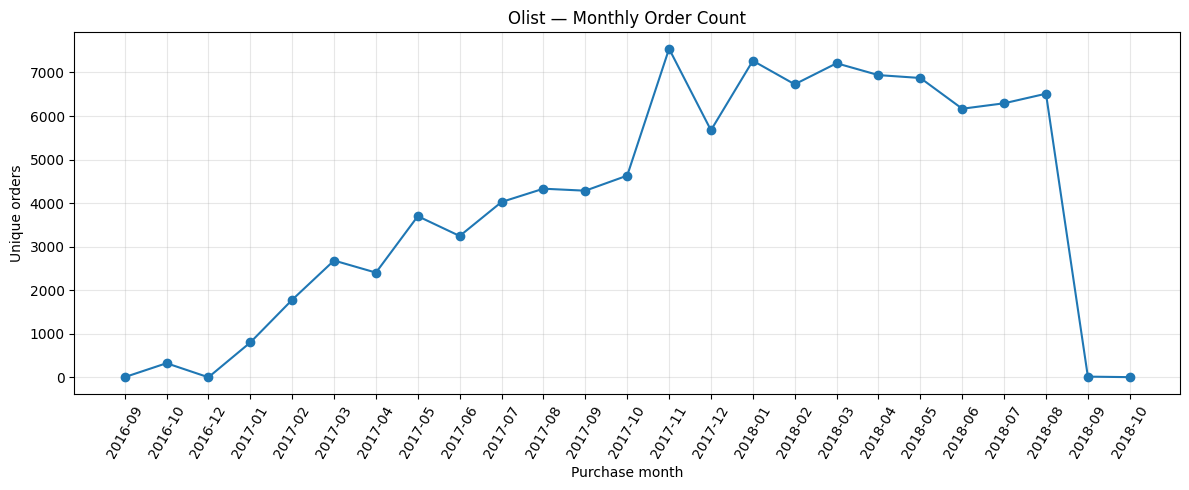

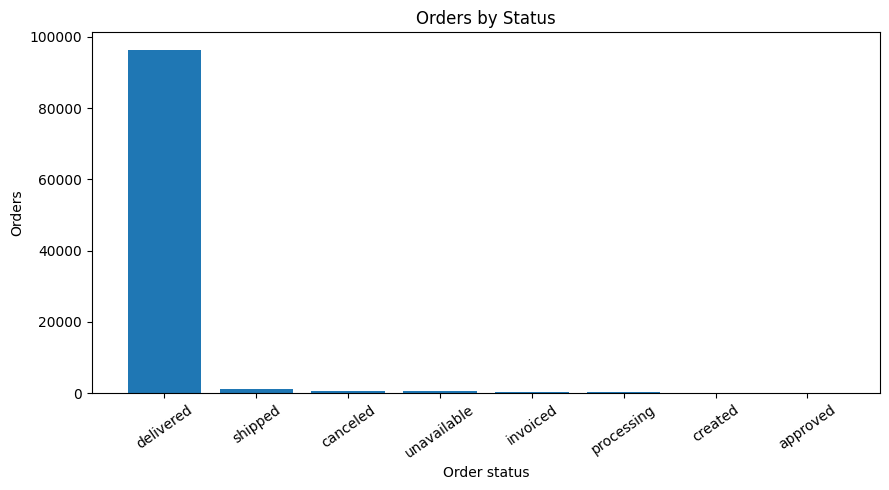

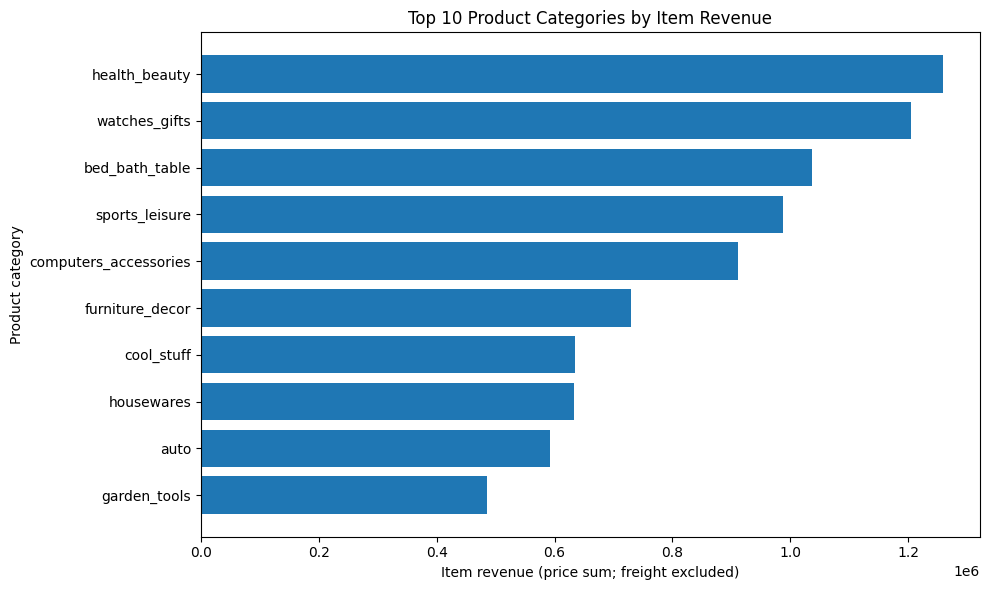

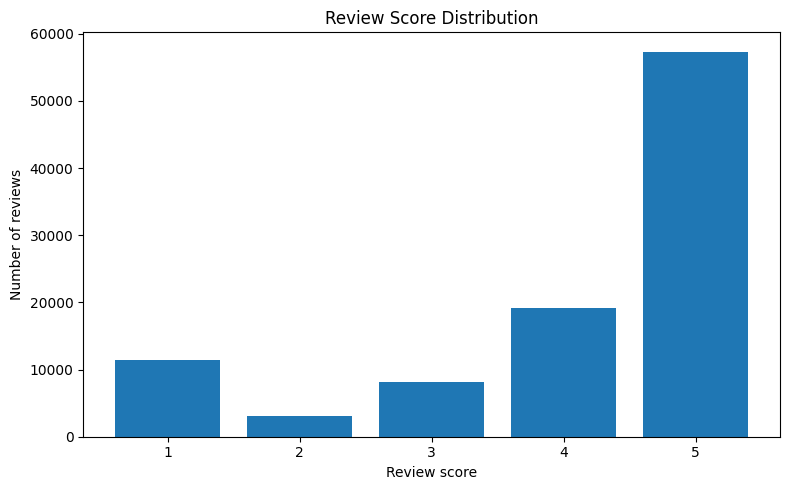

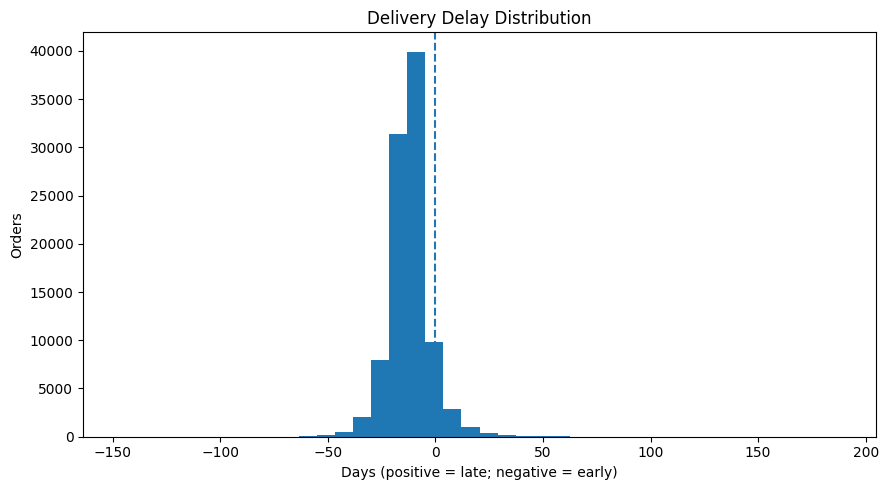

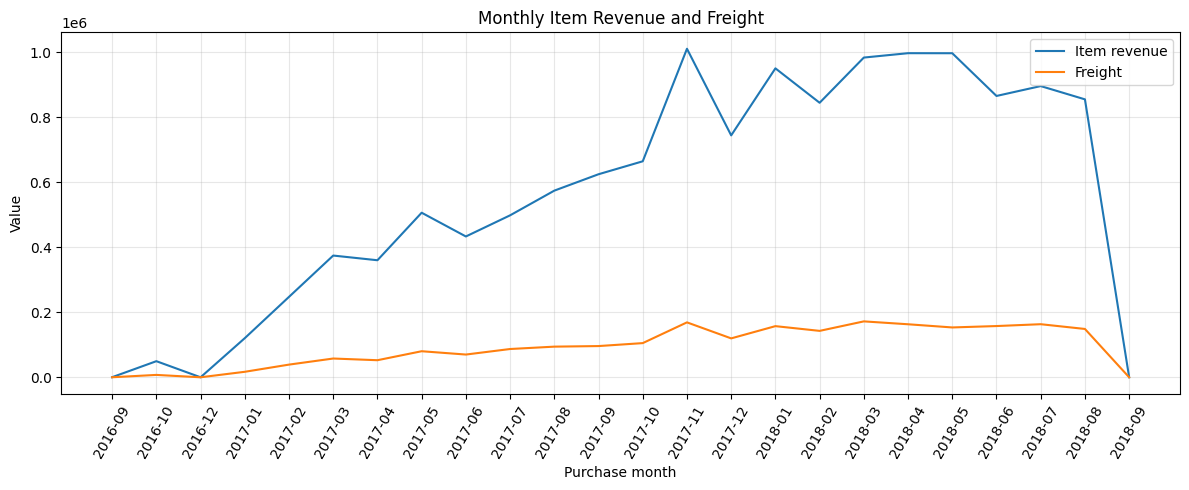

Charts saved to: /content/olist_python_output/figures


In [24]:
import matplotlib.pyplot as plt

FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 1) Monthly order trend
if not monthly_orders.empty:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(monthly_orders["PurchaseMonth"], monthly_orders["Orders"], marker="o")
    ax.set_title("Olist — Monthly Order Count")
    ax.set_xlabel("Purchase month")
    ax.set_ylabel("Unique orders")
    ax.tick_params(axis="x", rotation=60)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "monthly_order_trend.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# 2) Order status distribution
if not status_summary.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(status_summary["order_status"].astype(str), status_summary["Orders"])
    ax.set_title("Orders by Status")
    ax.set_xlabel("Order status")
    ax.set_ylabel("Orders")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "order_status_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# 3) Top categories by item revenue
if not category_sales.empty:
    top_categories = category_sales.head(10).sort_values("ItemRevenue")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top_categories["Category"].astype(str), top_categories["ItemRevenue"])
    ax.set_title("Top 10 Product Categories by Item Revenue")
    ax.set_xlabel("Item revenue (price sum; freight excluded)")
    ax.set_ylabel("Product category")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "top_categories_by_revenue.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# 4) Review score distribution
if not review_summary.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(review_summary["review_score"].astype(str), review_summary["Reviews"])
    ax.set_title("Review Score Distribution")
    ax.set_xlabel("Review score")
    ax.set_ylabel("Number of reviews")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "review_score_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# 5) Delivery delay distribution
if not delivery_summary.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(delivery_summary["Delivery_Delay_Days"], bins=40)
    ax.axvline(0, linestyle="--")
    ax.set_title("Delivery Delay Distribution")
    ax.set_xlabel("Days (positive = late; negative = early)")
    ax.set_ylabel("Orders")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "delivery_delay_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# 6) Monthly item and freight value trend
if not monthly_sales.empty:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(monthly_sales["PurchaseMonth"], monthly_sales["ItemRevenue"], label="Item revenue")
    ax.plot(monthly_sales["PurchaseMonth"], monthly_sales["FreightRevenue"], label="Freight")
    ax.set_title("Monthly Item Revenue and Freight")
    ax.set_xlabel("Purchase month")
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=60)
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "monthly_item_and_freight.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Charts saved to:", FIGURE_DIR)

## 22. علاقات إضافية وتلخيص EDA

هذه الجداول تلخّص العلاقات التي يمكن اختبارها مباشرة من البيانات المتاحة، دون تفسير سببي. الارتباط لا يعني السببية، كما أن بيانات Olist رصدية وليست تجربة مضبوطة.

In [25]:
# Delivery delay by order status; useful for comparing groups, not causal inference.
if not delivery_summary.empty:
    delay_by_status = (delivery_summary.groupby("order_status", dropna=False)["Delivery_Delay_Days"]
                       .agg(Orders="count", MeanDelayDays="mean", MedianDelayDays="median")
                       .reset_index().sort_values("Orders", ascending=False))
else:
    delay_by_status = pd.DataFrame(columns=["order_status", "Orders", "MeanDelayDays", "MedianDelayDays"])

# Review score by order status (join only the columns needed for analysis).
review_by_status = (eda_reviews[["order_id", "review_score"]]
                    .merge(eda_orders[["order_id", "order_status"]], on="order_id", how="left")
                    .groupby("order_status", dropna=False)
                    .agg(Reviews=("review_score", "count"), MeanReviewScore=("review_score", "mean"))
                    .reset_index().sort_values("Reviews", ascending=False))

print("Delivery delay by order status:")
display(delay_by_status)
print("Average review score by order status:")
display(review_by_status)

# Correlation matrix for numeric order-item measures (descriptive only).
correlation_cols = [c for c in ["price", "freight_value"] if c in eda_items.columns]
if len(correlation_cols) >= 2:
    item_correlation = eda_items[correlation_cols].apply(pd.to_numeric, errors="coerce").corr()
    display(item_correlation)
else:
    item_correlation = pd.DataFrame()
    print("Not enough numeric columns for a correlation matrix.")

Delivery delay by order status:


,order_status,Orders,MeanDelayDays,MedianDelayDays
1,delivered,96470,-11.875889,-12.0
0,canceled,6,-27.833333,-35.5


Average review score by order status:


,order_status,Reviews,MeanReviewScore
3,delivered,96361,4.155717
6,shipped,1043,2.008629
1,canceled,609,1.811166
7,unavailable,597,1.530988
4,invoiced,313,1.661342
5,processing,296,1.277027
2,created,3,2.333333
0,approved,2,2.5


,price,freight_value
price,1.000000,0.414204
freight_value,0.414204,1.000000


## 23. تحقق نهائي من التصدير والتكامل مع قاعدة البيانات

سيتم تصدير الجداول النظيفة والتقارير وملخصات EDA، بالإضافة إلى الرسوم. قبل استيراد CSV إلى قاعدة بيانات، راجع أنواع البيانات والمفاتيح الأساسية/الخارجية حسب مخطط قاعدة البيانات المستهدف؛ ملفات CSV لا تنشئ القيود العلائقية تلقائيًا.

In [26]:
# Export EDA and diagnostic reports alongside the cleaned tables.
outlier_report.to_csv(OUTPUT_DIR / "outlier_report_iqr.csv", index=False, encoding="utf-8-sig")
monthly_orders.to_csv(OUTPUT_DIR / "eda_monthly_orders.csv", index=False, encoding="utf-8-sig")
monthly_sales.to_csv(OUTPUT_DIR / "eda_monthly_sales.csv", index=False, encoding="utf-8-sig")
status_summary.to_csv(OUTPUT_DIR / "eda_order_status.csv", index=False, encoding="utf-8-sig")
category_sales.to_csv(OUTPUT_DIR / "eda_category_sales.csv", index=False, encoding="utf-8-sig")
review_summary.to_csv(OUTPUT_DIR / "eda_review_scores.csv", index=False, encoding="utf-8-sig")
delay_by_status.to_csv(OUTPUT_DIR / "eda_delivery_delay_by_status.csv", index=False, encoding="utf-8-sig")
review_by_status.to_csv(OUTPUT_DIR / "eda_reviews_by_status.csv", index=False, encoding="utf-8-sig")
if not item_correlation.empty:
    item_correlation.to_csv(OUTPUT_DIR / "eda_numeric_correlation.csv", encoding="utf-8-sig")

# Explicit export checks: files exist, are non-empty when expected, and can be read back.
export_check_rows = []
for table_name, frame in tables.items():
    filename = re.sub(r"[^A-Za-z0-9_-]+", "_", table_name).strip("_") + ".csv"
    target = OUTPUT_DIR / filename
    frame.to_csv(target, index=False, encoding="utf-8-sig")
    try:
        roundtrip = pd.read_csv(target, encoding="utf-8-sig", low_memory=False)
        export_check_rows.append({"Artifact": filename, "Exists": target.exists(),
                                  "Rows before export": len(frame), "Rows after read-back": len(roundtrip),
                                  "Columns before export": len(frame.columns), "Columns after read-back": len(roundtrip.columns),
                                  "Status": "PASS" if len(frame) == len(roundtrip) and len(frame.columns) == len(roundtrip.columns) else "CHECK"})
    except Exception as exc:
        export_check_rows.append({"Artifact": filename, "Exists": target.exists(),
                                  "Rows before export": len(frame), "Rows after read-back": np.nan,
                                  "Columns before export": len(frame.columns), "Columns after read-back": np.nan,
                                  "Status": f"ERROR: {exc}"})

export_validation_report = pd.DataFrame(export_check_rows)
export_validation_report.to_csv(OUTPUT_DIR / "export_validation_report.csv", index=False, encoding="utf-8-sig")
display(export_validation_report)
print("Export validation status counts:")
display(export_validation_report["Status"].value_counts(dropna=False).rename_axis("Status").to_frame("Count"))

,Artifact,Exists,Rows before export,Rows after read-back,Columns before export,Columns after read-back,Status
0,olist_customers_dataset.csv,True,99441,99441,5,5,PASS
1,olist_geolocation_dataset.csv,True,1000163,1000163,5,5,PASS
2,olist_order_items_dataset.csv,True,112650,112650,7,7,PASS
3,olist_order_payments_dataset.csv,True,103886,103886,5,5,PASS
4,Order_Payments_Summary.csv,True,99440,99440,2,2,PASS
5,Order_Reconciliation.csv,True,98666,98666,9,9,PASS
6,Order_Reconciliation_Exceptions.csv,True,371,371,9,9,PASS
7,olist_order_reviews_dataset.csv,True,99224,99224,7,7,PASS
8,olist_orders_dataset.csv,True,99441,99441,12,12,PASS
9,olist_products_dataset.csv,True,32951,32951,10,10,PASS


Export validation status counts:


,Count
Status,
PASS,13


## 24. تصدير الجداول النظيفة وتقارير الفحص

يتم حفظ كل جدول في ملف CSV داخل `olist_python_output`، ثم تجميع جميع الملفات في ZIP واحد. في Colab يمكنك تنزيل الـ ZIP من الخلية التالية.

In [27]:
# Include CSV reports and visualization PNG files in the ZIP.
zip_path = DATA_DIR / "olist_python_outputs.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file():
            archive.write(path, arcname=str(path.relative_to(OUTPUT_DIR)))

exported_files = [p for p in OUTPUT_DIR.rglob("*") if p.is_file()]
print("Exported", len(exported_files), "files to", OUTPUT_DIR)
print("ZIP archive:", zip_path)
print("The ZIP includes cleaned CSV tables, quality/reconciliation/EDA reports, and charts.")
print("In Google Colab, run the next cell to download the ZIP archive.")

Exported 29 files to /content/olist_python_output
ZIP archive: /content/olist_python_outputs.zip
The ZIP includes cleaned CSV tables, quality/reconciliation/EDA reports, and charts.
In Google Colab, run the next cell to download the ZIP archive.


In [28]:
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Not running in Google Colab. ZIP saved at:", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 25. ملاحظات قبل اعتماد النتائج

1. **استبدال المدن:** الاستعلام الأصلي يستبدل النصين الحرفيين `??????` و`?????` داخل `customer_city`. لم نستنتج المدن الأصلية المحتملة، لأن الملف لا يثبت هل السبب Encoding أم نص فعلي.
2. **تعويض السعر:** القيم الفارغة أو التي تعذّر تحويلها رقميًا في `price` تصبح `145.95`، امتثالًا لـ M. هذه قاعدة أعمال مؤثرة ويجب تأكيدها قبل اعتماد المجاميع.
3. **المطابقة المالية:** منطق M يستبدل `Difference = null` بصفر؛ لذلك الطلب الذي لا يوجد له سجل دفع قد يصنف `Match`. العمود `Missing Payment Record` إضافي للتدقيق، ولا يغيّر حالة المطابقة الأصلية.
4. **CSV والاقتباس:** يستخدم Python محلل CSV القياسي لدعم الحقول النصية التي تحتوي على فواصل، خصوصًا تعليقات المراجعات. قد يختلف هذا عن بعض مصادر M التي استخدمت `QuoteStyle.None`؛ وهو اختلاف مقصود لتفادي فصل حقول CSV المقتبسة خطأً.
5. **الموقع:** الإحداثيات في نتيجة M النهائية نصوص بسبب التحويل النهائي إلى `type text`. إذا كان الهدف خرائط أو حساب مسافات، أنشئ نسخة رقمية منفصلة للإحداثيات ولا تغيّر النسخة المطابقة دون توثيق.
6. **الاختبار النهائي:** لم يتمكن هذا Notebook من مقارنة النتائج الفعلية ببيانات CSV هنا لأن الملف المرفوع يحتوي أكواد M فقط وليس ملفات البيانات التسعة. بعد رفع CSVs وتشغيل كل الخلايا، راجع `data_quality_report.csv` و`parse_issues_report.csv` و`reconciliation_summary.csv`.

6. **Outliers:** تم إنشاء تقرير IQR تشخيصي فقط؛ لم يتم حذف القيم الشاذة أو تعديلها لأن ذلك سيغيّر البيانات التي أكدت صحة تنظيفها في Power Query.
7. **EDA:** الرسوم والجداول تحليل وصفي، وليست دليلًا على علاقة سببية.
8. **Database integration:** CSV export خطوة تجهيز؛ يلزم تحديد أنواع البيانات والمفاتيح والقيود عند التحميل إلى قاعدة البيانات المستهدفة.